# Phase 0 - dataset screening, cleaning and the train/test split

**Question.** Which public dataset fits the brief best, and how do we clean and split it without leaking information into the test set?

**Brief and report.** Part A (dataset characteristics) and the data side of Part C. Report Sections 1.2 and 4.2; Appendix F extends the screening with a modelling check (`scripts/screen_candidate_models.py`).

**Inputs and outputs.** The raw files in `data/raw/` go in. Out come the screening scorecard (`results/phase0_scorecard.csv`), the cleaned data (`data/processed/cleaned.csv`) and the train/test row indices.

**Why it comes first.** The split is made here, before anything is fitted, so the test set cannot influence any later choice.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

### 1. Screen four candidates, then clean and split the chosen one
`screen()` in `src/selection.py` reads each candidate exactly as published and counts ten kinds of data-quality issue: missing values (including tokens such as "?" and "unknown"), duplicates, IQR outliers, skewed fields, identical rows with different labels, implausible values and four kinds of inconsistency. Nothing is fitted. It then calls `clean_and_split()` in `src/data.py` for the hotel data.

**How to read the table.** One row per dataset. A non-zero count means the issue is present, which is what Part C needs to demonstrate. The hotel data show the most kinds of issue.

In [2]:
from src.selection import screen
scorecard = screen()
display(scorecard)

Phase 0 | clean and split: 119390 raw rows -> 87396 after removing 31994 exact duplicates; 69877 train / 17519 test, 78860 booking groups, none split.


Phase 0 | screening: Four public candidates screened; Hotel Booking Demand cleaned and split.


,dataset,rows,attributes,target,classes,missing_cells,duplicates,iqr_outlier_cells,skewed_features,imbalance_ratio,conflicting_label_rows,implausible_rows,whitespace_rows,case_variant_groups,mixed_numeric_rows,semantic_variant_rows,varying_numeric_features,source,licence
0,Hotel Booking Demand,119390,31,is_canceled,2,129425,31994,95615,15,1.700,2209,181,0,0,0,1169,19,https://raw.githubusercontent.com/rfordatascie...,"CC BY 4.0 (Antonio, de Almeida and Nunes, 2019)"
1,Adult,48842,14,income,2,6465,52,23276,3,3.179,10,0,0,0,0,0,6,https://archive.ics.uci.edu/static/public/2/ad...,CC BY 4.0 (UCI)
2,Bank Marketing,41188,20,y,2,12718,12,13425,5,7.877,0,0,0,0,0,0,10,https://archive.ics.uci.edu/static/public/222/...,CC BY 4.0 (UCI)
3,Diabetes,101766,49,readmitted,3,192849,0,62720,9,4.831,0,0,0,0,294257,0,13,https://archive.ics.uci.edu/static/public/296/...,CC BY 4.0 (UCI)


### 2. What the cleaning removed, and how the split was made
`clean_and_split()` trims text, turns missing-value tokens into blanks, merges the meal code "Undefined" into "SC" (the source defines both as "no meal") and removes exact duplicate records. None of these steps looks at the outcome. It then groups bookings that are identical on all 20 booking-time fields and uses `StratifiedGroupKFold`, so no group is split between training and test.

**How to read the output.** The counts table shows the rows removed at each step. The manifest shows the 80/20 sizes, the cancellation rate on each side, and that no booking group spans the split.

,step,rows,removed
0,raw source rows,119390,0
1,"missing tokens, trimming, types, meal codes",119390,0
2,exact duplicate records (all 32 columns),87396,31994


{'seed': 42,
 'method': 'StratifiedGroupKFold(5), first fold held out',
 'rows': 87396,
 'train_rows': 69877,
 'test_rows': 17519,
 'train_positive_fraction': 0.27592770153269314,
 'test_positive_fraction': 0.2707917118556995,
 'booking_groups': 78860,
 'rows_in_shared_groups': 14184,
 'groups_with_both_labels': 1068,
 'group_key_columns': ['hotel',
  'lead_time',
  'arrival_date_month',
  'arrival_date_week_number',
  'arrival_date_day_of_month',
  'stays_in_weekend_nights',
  'stays_in_week_nights',
  'adults',
  'children',
  'babies',
  'meal',
  'market_segment',
  'distribution_channel',
  'is_repeated_guest',
  'previous_cancellations',
  'previous_bookings_not_canceled',
  'reserved_room_type',
  'agent',
  'company',
  'customer_type'],
 'outcome_fields_never_used': ['reservation_status',
  'reservation_status_date',
  'assigned_room_type',
  'booking_changes',
  'days_in_waiting_list'],
 'source_sha256': '7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06',
 'po

**reports/figures/fig_C_00_candidate_quality.png**

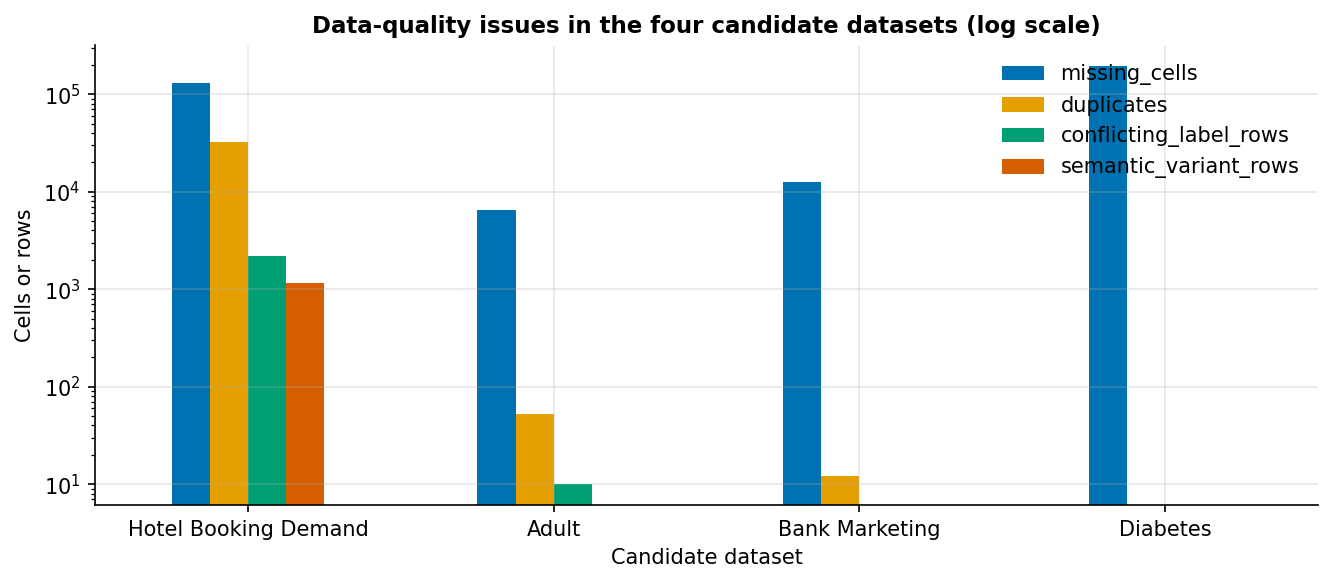

In [3]:
display(results('phase0_cleaning_counts.csv'))
import json
display(json.loads((ROOT / 'data/processed/split_manifest.json').read_text(encoding='utf-8')))
show('fig_C_00_candidate_quality.png')